In [49]:
using Fluidum
using PyPlot
include("Libs/plotter.jl");
directory = "Plots/Edge_Studys/nsigma_newPlots_0pT/";
save_plots = true;
if save_plots && !isdir(directory)
    mkdir(directory);
    mkdir(directory*"Rescaled/");
end

In [50]:
no_of_lists = 19;
kernel_directory = "Kernels_Edge_Study/PbPb_276_PCE_nsigma_fix_0/";
kernel_folder_cuts = ["/home/tim/Studium/Masterarbeit/Fluidum/" * kernel_directory * "list_" * string(i) * "/" for i in 0:no_of_lists-1];
println(kernel_folder_cuts);
PCE = true

# for folder in kernel_folder_cuts
#     print("Saving particles for folder: " * folder);
#     save_all_particles(folder; Tchem=145, Tkin=122, type = "thermal", PCE_bool = PCE)
#     save_all_particles(folder; Tchem=145, Tkin=122, type = "total", PCE_bool = PCE)
#     println(" ... done \n");
# end

dic_cuts = [dictionary_pions(folder) for folder in kernel_folder_cuts];

["/home/tim/Studium/Masterarbeit/Fluidum/Kernels_Edge_Study/PbPb_276_PCE_nsigma_fix_0/list_0/", "/home/tim/Studium/Masterarbeit/Fluidum/Kernels_Edge_Study/PbPb_276_PCE_nsigma_fix_0/list_1/", "/home/tim/Studium/Masterarbeit/Fluidum/Kernels_Edge_Study/PbPb_276_PCE_nsigma_fix_0/list_2/", "/home/tim/Studium/Masterarbeit/Fluidum/Kernels_Edge_Study/PbPb_276_PCE_nsigma_fix_0/list_3/", "/home/tim/Studium/Masterarbeit/Fluidum/Kernels_Edge_Study/PbPb_276_PCE_nsigma_fix_0/list_4/", "/home/tim/Studium/Masterarbeit/Fluidum/Kernels_Edge_Study/PbPb_276_PCE_nsigma_fix_0/list_5/", "/home/tim/Studium/Masterarbeit/Fluidum/Kernels_Edge_Study/PbPb_276_PCE_nsigma_fix_0/list_6/", "/home/tim/Studium/Masterarbeit/Fluidum/Kernels_Edge_Study/PbPb_276_PCE_nsigma_fix_0/list_7/", "/home/tim/Studium/Masterarbeit/Fluidum/Kernels_Edge_Study/PbPb_276_PCE_nsigma_fix_0/list_8/", "/home/tim/Studium/Masterarbeit/Fluidum/Kernels_Edge_Study/PbPb_276_PCE_nsigma_fix_0/list_9/", "/home/tim/Studium/Masterarbeit/Fluidum/Kernels_E

In [51]:
#define a radial grid
rmax = 40;
gridpoints=500;
grid_params = Fluidum.GridParameters(rmax, gridpoints);
disc=CartesianDiscretization(OriginInterval(gridpoints,rmax)) 

#decide the detector to use 
det = :ALICE276;
det_name = detector_dict[det].name; 
dσ_QQdy = detector_dict[det].dσ_QQdy;
σ_in = detector_dict[det].σ_in;

tspan = (0.91477, 20);
norm = 34.487;
rdrop = 8.;
tau0 = tspan[1];

initial_params = Fluidum.InitialParameters(norm, tau0, rdrop);

#take the tabulated data 
ent276 = TabulatedData(string(@__DIR__, "/TabulatedData/EntropyProfile_", det_name, "Duke.txt"));

list = readresonancelist();

┌ Warning: centrality chosen is not a multiple of the bin size. Using 0-4 instead
└ @ Fluidum ~/.julia/dev/Fluidum.jl/src/fluidevo/map_profile.jl:29
sys:1: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


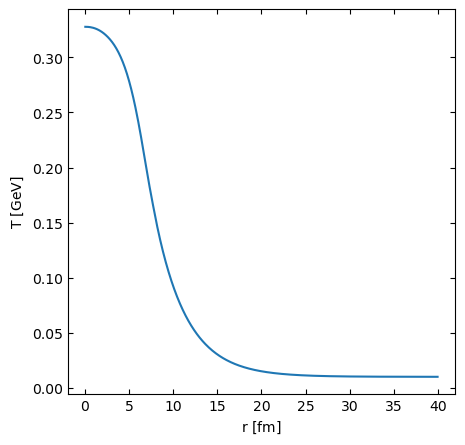

In [52]:
fields = Fluidum.initialize_fields(ent276, 0, 5; grid_params, initial_params);
#print(typeof(fields))
#eos = Heavy_Quark();
eos = FluiduMEoS();

plot_initial_field(fields; save=save_plots, path="Plots/initial_field_pce.png");

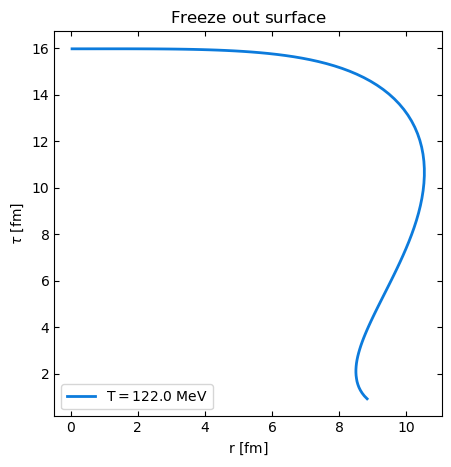

In [53]:
####################################zero diffusion
viscosity = QGPViscosity(2.0874/3.5,0.2); #or, ZeroViscosity();
bulk = SimpleBulkViscosity(0.017963,15.0); #or, ZeroBulkViscosity();

##########################no diffusion
diffusion = ZeroDiffusion();
params=Fluidum.FluidProperties(eos,viscosity,bulk,diffusion);
fo = freeze_out_routine(fields.discrete_field, Fluidum.matrxi1d_visc!_Tscale, params, fields.initial_field, tspan; Tfo = 0.1215);
plot_fo_surface(fo;save=save_plots);

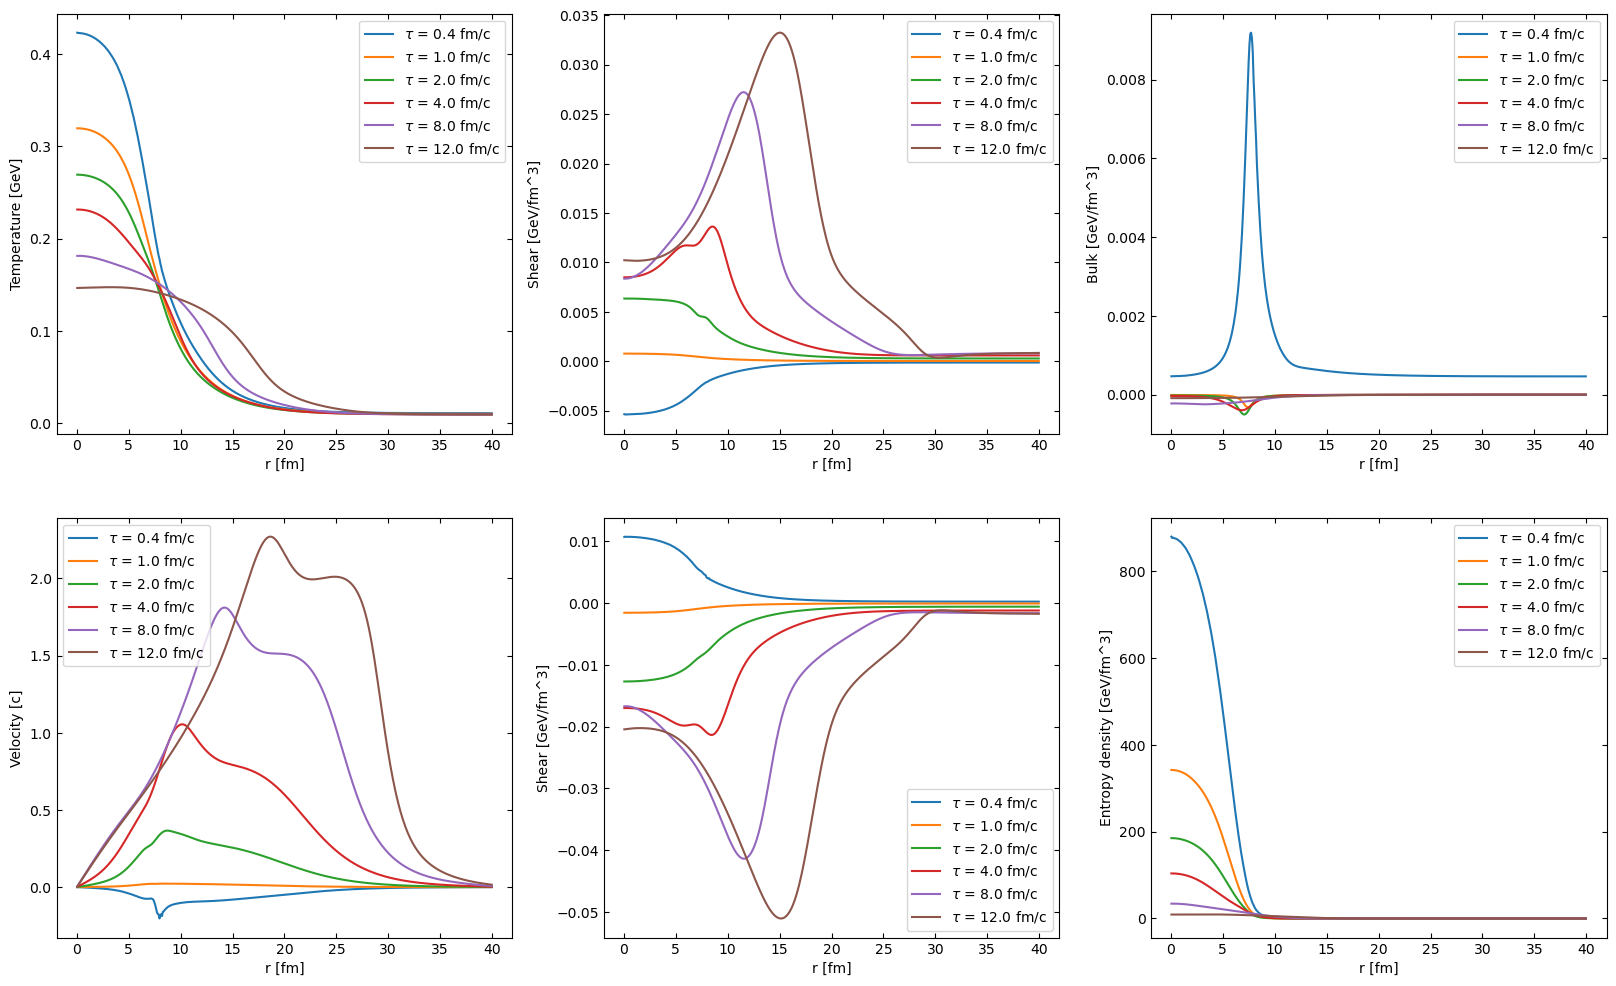

In [54]:
result_field = oneshoot(fields.discrete_field, Fluidum.matrxi1d_visc!, params, fields.initial_field, tspan; reltol = 1e-8);

times = [0.4, 1.0, 2.0, 4.0, 8.0, 12.0]
radius = zeros(gridpoints+2)
[radius[i]= disc.grid[i][1] for i in eachindex(disc.grid[1:end])] 

plot_result_fields(result_field, radius, times, params; save=save_plots);

Here begins my own plotting routine

In [55]:
include("Libs/data_lib.jl");

extraction_end_pion = 41; #number of data points to extract
filename_pion = "ExperimentalData/HEPData-ins1222333-v1-Table_1.csv"

data_pion = get_data(filename_pion, extraction_end_pion);
println("Pion data extracted: ", data_pion.pt);
mult_pion_data = calculate_yield(data_pion; verbose=true);
mult_pion_data_excess = calculate_yield(data_pion; excess=true, verbose=true);
println("Pion data multiplicity (0.1 - 3.0 GeV/c): ", mult_pion_data[1], " +- ", mult_pion_data[2])
println("Pion data multiplicity (0.1 - 0.5 GeV/c): ", mult_pion_data_excess[1], " +- ", mult_pion_data_excess[2])

Pion data extracted: [0.11, 0.13, 0.15000000000000002, 0.16999999999999998, 0.19, 0.225, 0.275, 0.32499999999999996, 0.375, 0.42500000000000004, 0.475, 0.525, 0.575, 0.625, 0.675, 0.725, 0.775, 0.825, 0.875, 0.925, 0.975, 1.05, 1.15, 1.25, 1.35, 1.45, 1.55, 1.65, 1.75, 1.85, 1.95, 2.05, 2.1500000000000004, 2.25, 2.3499999999999996, 2.45, 2.55, 2.6500000000000004, 2.75, 2.8499999999999996, 2.95]
Yield: 682.1370916347523 + 0.46227961380718136 (stat) - 0.46227961380718136 (stat) + 11.575380312091593 (syst) - 11.575380312091593 (syst)
Yield: 682.1370916347523 ± 11.584607538060984 (total) + 11.584607538060984 (total) - 11.584607538060984 (total)

Yield: 397.03432248104536 + 0.3708293504388739 (stat) - 0.3708293504388739 (stat) + 10.904840995444424 (syst) - 10.904840995444424 (syst)
Yield: 397.03432248104536 ± 10.911144373670082 (total) + 10.911144373670082 (total) - 10.911144373670082 (total)

Pion data multiplicity (0.1 - 3.0 GeV/c): 682.1370916347523 +- 11.584607538060984
Pion data multip

In [56]:
include("Libs/results_lib.jl");

rescale_thermal::Bool = true;
rescale_total_refregion::Bool = true;

#@show dic.pion
use_3d_kernel = false

results_pion_cuts = get_results_list(fo, dic_cuts, params, data_pion.pt; interpolate_3d=use_3d_kernel);

REFERENCE_MULT_TOTAL = 296.9204802282646
REFERENCE_MULT_THERMAL = 346.68494311992293

if rescale_thermal
    println("Rescaling to match all thermal spectra in (0.1 - 3.0 GeV/c) range, then match total spectra in (0.5 - 3.0 GeV/c) range.")
    rescaled_thermal_result_pion_cuts = rescale_result_list_thermal(results_pion_cuts; reference_mult = REFERENCE_MULT_THERMAL);
    if rescale_total_refregion
        println("Rescaling total result to match in (0.5 - 3.0 GeV/c) range.")
        rescaled_result_pion_cuts = rescale_result_list(rescaled_thermal_result_pion_cuts; reference_mult = REFERENCE_MULT_TOTAL); 
    else
        rescaled_result_pion_cuts = rescaled_thermal_result_pion_cuts;
    end
else
    if rescale_total_refregion
        println("Rescaling total result to match in (0.5 - 3.0 GeV/c) range.")
        rescaled_result_pion_cuts = rescale_result_list(results_pion_cuts; reference_mult = REFERENCE_MULT_TOTAL);
    else
        rescaled_result_pion_cuts = results_pion_cuts;
    end
end

Rescaling to match all thermal spectra in (0.1 - 3.0 GeV/c) range, then match total spectra in (0.5 - 3.0 GeV/c) range.
Reference thermal multiplicities (0.1 - 3.0 GeV/c): [346.68494311992293, 345.00033911097944, 348.90134213549004, 346.68494311992293, 346.68494311992293, 318.7235953940039, 294.509493881545, 344.3815837686149, 350.26797620197146, 346.68494311992293, 346.68494311992293, 282.5658517928017, 203.42205188107616, 343.81665998411506, 351.73394001823453, 346.68494311992293, 346.68494311992293, 268.7873316986543, 194.90339647590548]
Scaling factors: [1.0, 1.0048829053712947, 0.9936474907147064, 1.0, 1.0, 1.0877291425234878, 1.1771605001615448, 1.006688392933507, 0.9897705947289269, 1.0, 1.0, 1.226917339516801, 1.7042643111406652, 1.0083424786220085, 0.9856454088620227, 1.0, 1.0, 1.2898113200833512, 1.7787527020483767]
Rescaling total result to match in (0.5 - 3.0 GeV/c) range.
Reference multiplicities (0.5 - 3.0 GeV/c): [296.9204802282646, 286.972378176252, 305.61849064962286, 

ResultsList([[(400.94178173921557, 0.005964256008713753), (391.01798946842484, 0.003743158679499592), (379.38222395623774, 0.003861861023407659), (364.3190311266163, 0.004521702848959613), (348.017210305952, 0.0026154081577798305), (317.02314329884706, 0.0015711724856826148), (271.9088563173381, 0.003261288507132032), (229.98067428044442, 0.0023604467225366577), (193.10731053442694, 0.0018218383930559412), (161.2293810925379, 0.0014652499808097685)  …  (0.7509791652866286, 1.090643266352711e-5), (0.568265699253122, 7.640544544694223e-6), (0.4124097683769914, 5.852078886436782e-6), (0.31149346156838614, 4.603253095403871e-6), (0.22396652426355426, 3.075612226733943e-6), (0.17293727390728605, 2.468270943453624e-6), (0.12190789424786112, 1.8069539580627947e-6), (0.09489012300544496, 1.3734144718246509e-6), (0.07183059823808323, 1.0078165509055579e-6), (0.048771145344515016, 6.995888939143453e-7)], [(400.59428606133815, 0.004168784858032293), (390.69691068330263, 0.0038159302075679857), (3

## Look at Reference

Total uncertainties: ([210.34257771549724, 177.18069872308325, 158.11388300841898, 141.088624630053, 128.06248474865697, 60.521153326750145, 47.11528414431988, 37.91319031682773, 27.81150840928985, 21.311499243366246, 16.710774967068403, 9.912618221237011, 7.810249675906654, 6.711929677819934, 5.61426753904728, 4.601141162798638, 3.9706044879841658, 3.3309608223454084, 2.9091063920042526, 2.4399385238157127, 1.9701776569639602, 1.5546382215808283, 1.134416149391395, 0.8927485648266258, 0.6519202405202649, 0.4758571214135604, 0.35483094566286066, 0.26704681237565825, 0.20032473636573195, 0.15119854496654392, 0.11672617529928753, 0.0902551937563706, 0.07085795650454507, 0.05481204247243483, 0.04556237482836029, 0.03600472191254919, 0.029080061898145954, 0.02411057859114957, 0.01923460423299632, 0.01603277892319357, 0.013566502865514016], [210.34257771549724, 177.18069872308325, 158.11388300841898, 141.088624630053, 128.06248474865697, 60.521153326750145, 47.11528414431988, 37.91319031682

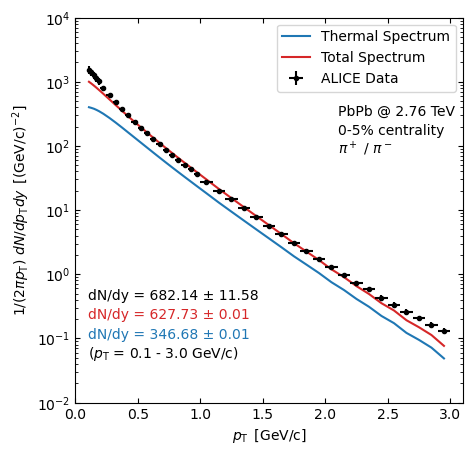

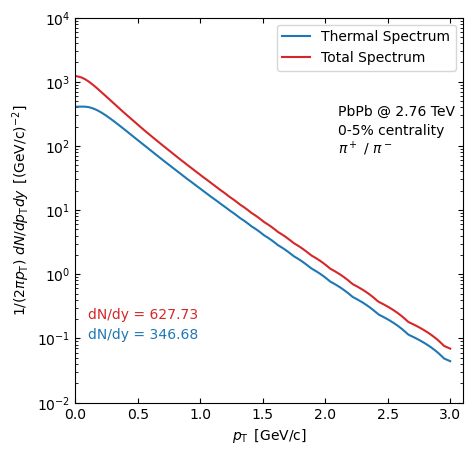

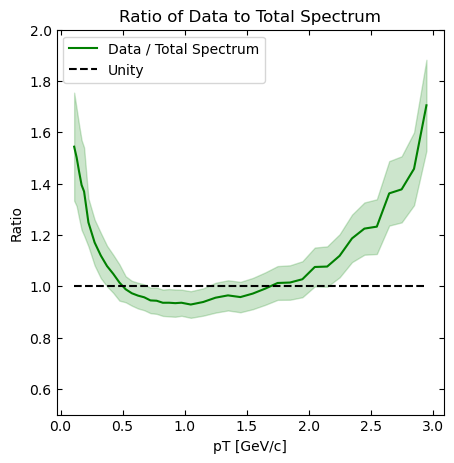

In [57]:
index = 1    # 1 : reference

test_reference = get_results_from_list_helper(rescaled_result_pion_cuts, index)

pT_range = collect(0:0.01:3)
test_reference_pT = get_results(fo,  getfield(dic_cuts[index], :pion), params, pT_range; interpolate_3d=use_3d_kernel)

plot_spectra(test_reference, data_pion, mult_pion_data; save=save_plots)
plot_spectra_colors(test_reference_pT, pT_range, mult_pion_data; save=save_plots)
plot_ratio(test_reference, data_pion; save = save_plots)

Pion excess multiplicity (0.1 - 0.5 GeV/c) for 0-5% centrality: 66.22433719143106 +- 10.911144373670082 (exp) +- 5.000002427358482 (model)
Relative pion excess (0.1 - 0.5 GeV/c) for 0-5% centrality: 0.09708361853293065 +- 0.01531824578799246 (exp) +- 0.007329908443148719 (model)
Total uncertainties: ([210.34257771549724, 177.18069872308325, 158.11388300841898, 141.088624630053, 128.06248474865697, 60.521153326750145, 47.11528414431988, 37.91319031682773, 27.81150840928985, 21.311499243366246, 16.710774967068403, 9.912618221237011, 7.810249675906654, 6.711929677819934, 5.61426753904728, 4.601141162798638, 3.9706044879841658, 3.3309608223454084, 2.9091063920042526, 2.4399385238157127, 1.9701776569639602, 1.5546382215808283, 1.134416149391395, 0.8927485648266258, 0.6519202405202649, 0.4758571214135604, 0.35483094566286066, 0.26704681237565825, 0.20032473636573195, 0.15119854496654392, 0.11672617529928753, 0.0902551937563706, 0.07085795650454507, 0.05481204247243483, 0.04556237482836029, 0

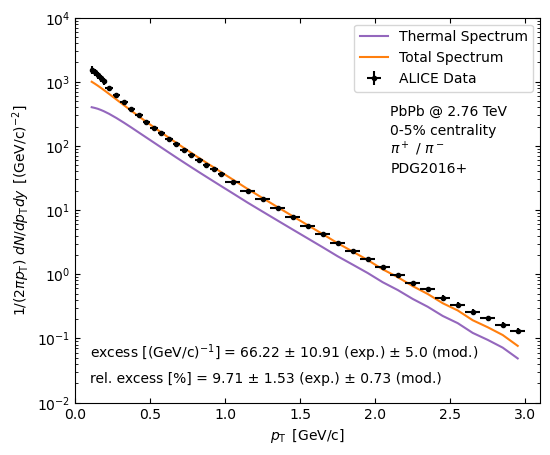

In [58]:
excess, excess_err_exp, excess_err_mod = calculate_excess(test_reference, mult_pion_data_excess)

println("Pion excess multiplicity (0.1 - 0.5 GeV/c) for 0-5% centrality: ", excess, " +- ", excess_err_exp, " (exp) +- ", excess_err_mod, " (model)")

rel_excess_ref, rel_excess_ref_err_exp, rel_excess_ref_err_mod = calculate_rel_excess(test_reference, mult_pion_data, mult_pion_data_excess)

println("Relative pion excess (0.1 - 0.5 GeV/c) for 0-5% centrality: ", rel_excess_ref, " +- ", rel_excess_ref_err_exp, " (exp) +- ", rel_excess_ref_err_mod, " (model)")

excess_data = (excess, excess_err_exp, excess_err_mod)
rel_excess_data = (rel_excess_ref, rel_excess_ref_err_exp, rel_excess_ref_err_mod)

plot_spectra_with_excess(test_reference, data_pion, excess_data, rel_excess_data; save=save_plots)

### All samples

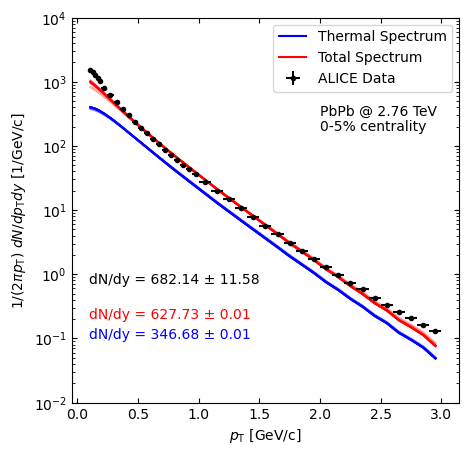

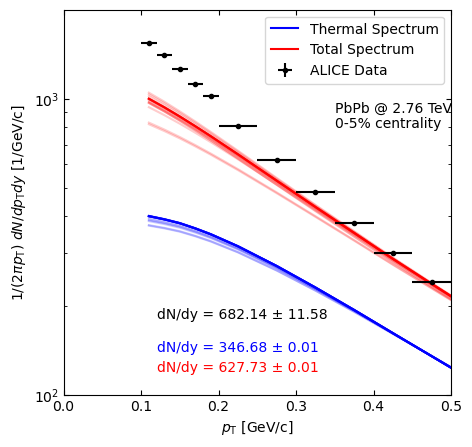

In [59]:
include("Libs/plotter_sampling.jl");

plot_sample_spectra(rescaled_result_pion_cuts, data_pion, mult_pion_data; save=save_plots)
plot_sample_spectra(rescaled_result_pion_cuts, data_pion, mult_pion_data; excess=true, save=save_plots)

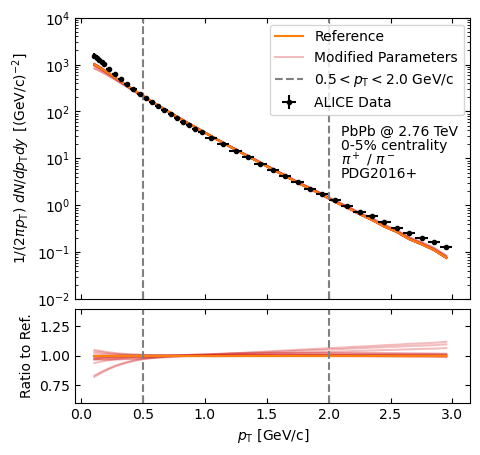

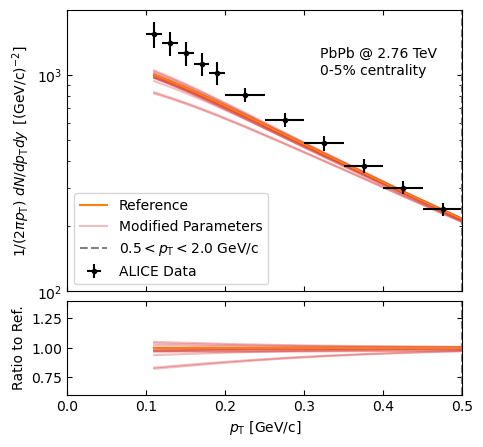

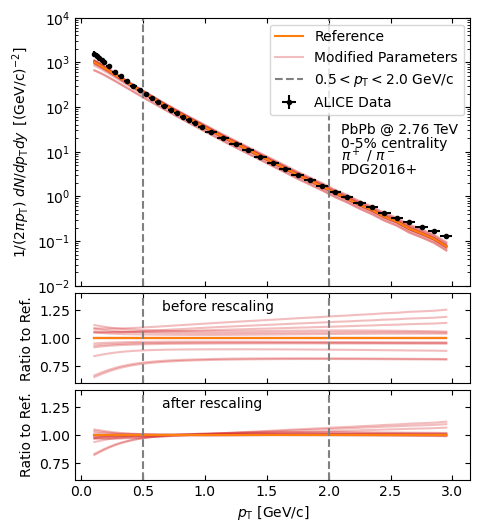

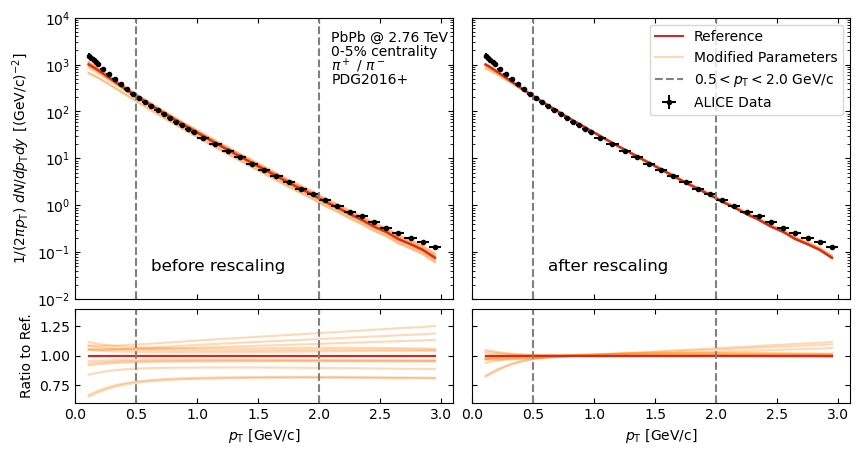

In [60]:
plot_sample_spectra_relative(rescaled_result_pion_cuts, data_pion, mult_pion_data; save=save_plots)
plot_sample_spectra_relative(rescaled_result_pion_cuts, data_pion, mult_pion_data; excess=true, save=save_plots)

if rescale_total_refregion == true
    plot_sample_spectra_relative_3(rescaled_result_pion_cuts, rescaled_thermal_result_pion_cuts, data_pion, mult_pion_data; excess=false, save=save_plots)
    plot_sample_spectra_relative_4(rescaled_result_pion_cuts, rescaled_thermal_result_pion_cuts, data_pion, mult_pion_data; excess=false, save=save_plots)
end

length excess1: 6 length excess2: 6 length excess3: 6
length excess1 x: [2, 3, 4, 5, 6, 7] length excess2 x: [2, 3, 4, 5, 6, 7] length excess3 x: [2, 3, 4, 5, 6, 7]
Mean Excess: 70.88172801986576 ± 10.038870576495452


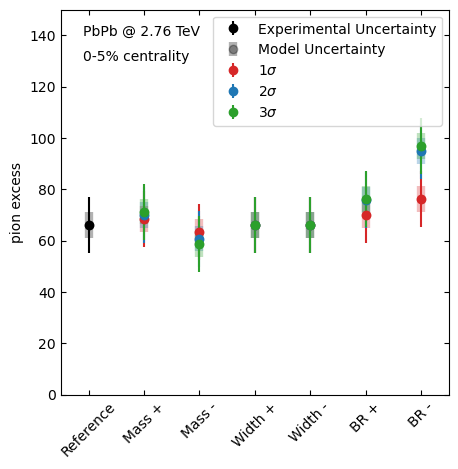

In [61]:
excess, excess_err_exp, excess_err_mod = calculate_excess_list(rescaled_result_pion_cuts, mult_pion_data_excess)

plot_excess(excess, excess_err_exp, excess_err_mod; nsigma=true, edge=true, save=save_plots)

Mean relative Excess: 0.10391126488957898 ± 0.014716793295079647


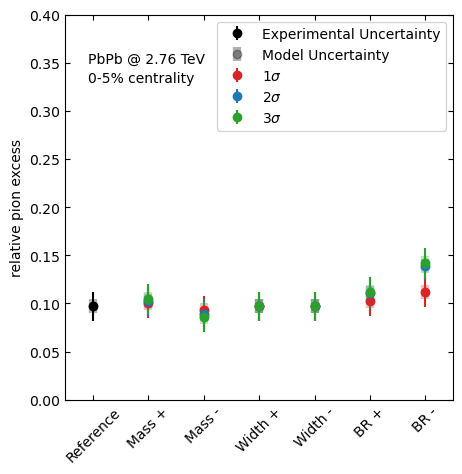

In [62]:
rel_excess, rel_excess_err_exp, rel_excess_err_mod = calculate_rel_excess_list(rescaled_result_pion_cuts, mult_pion_data, mult_pion_data_excess)

plot_rel_excess(rel_excess, rel_excess_err_exp, rel_excess_err_mod; nsigma=true, edge=true, save=save_plots)

sys:1: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.


[4.070197673150459e-6, 4.201633984760514e-6, 4.091887499232316e-6, 4.070197673150459e-6, 4.070197673150459e-6, 4.253256591485104e-6, 4.016728340407997e-6, 4.21345034626043e-6, 4.124165607752331e-6, 4.070197673150459e-6, 4.070197673150459e-6, 4.242383352714484e-6, 3.6251826481497637e-6, 4.006881436385888e-6, 4.296168609287578e-6, 4.070197673150459e-6, 4.070197673150459e-6, 4.148417805494445e-6, 3.193496517123193e-6]


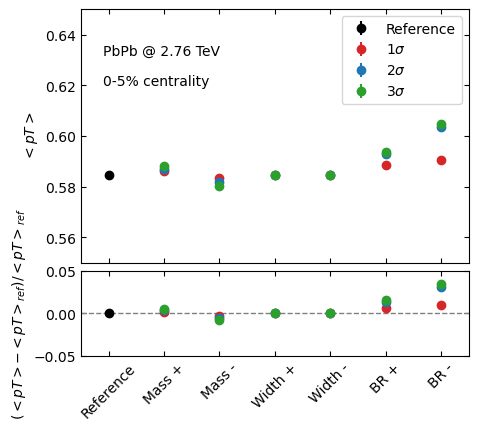

In [63]:
mean_pT_list, mean_pT_err_list = mean_pt_spectra_list(results_pion_cuts.spectra_total, data_pion.pt, data_pion.ptp, data_pion.ptm)
plot_mean_pT(mean_pT_list, mean_pT_err_list; nsigma=true, edge=true, save=save_plots)
println(mean_pT_err_list)

Spectra masses: 6
Spectra masses: 6


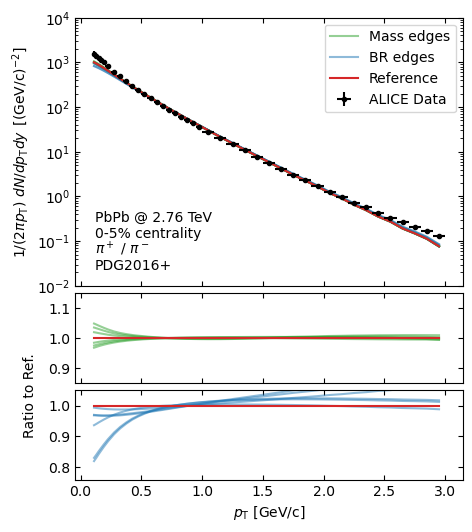

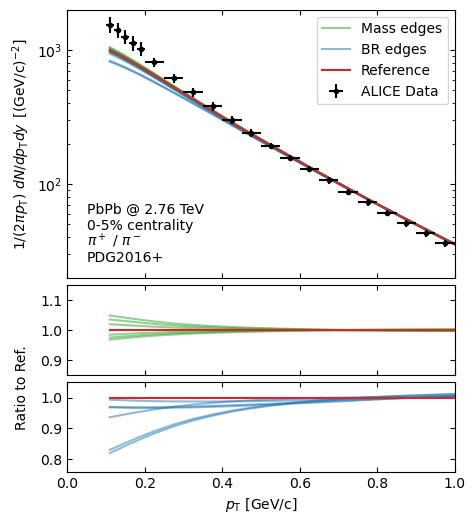

In [64]:
include("Libs/plotter_final.jl");
QM_bool = false
plot_spectra_relative_colors(rescaled_result_pion_cuts, data_pion; QM=QM_bool, save=save_plots)
plot_spectra_relative_colors(rescaled_result_pion_cuts, data_pion; excess=true, QM=QM_bool, save=save_plots)

Before plotting: 191919
After plotting: 191919
Mean relative Excess: 0.10391126488957898 ± 0.014716793295079647
Reloaded results from ExcessData/relative_excess_results.txt
rel_excess = [0.09708361853293065, 0.10042197897271804, 0.09287180511998139, 0.09708361853293065, 0.09708361853293065, 0.10260027791565021, 0.11163396686793658, 0.10276498653562881, 0.08919381589607256, 0.09708361853293065, 0.09708361853293065, 0.11108827027958756, 0.1393522122057304, 0.10461339638872946, 0.08601281317263475, 0.09708361853293065, 0.09708361853293065, 0.11198507113707698, 0.14219010867973925]


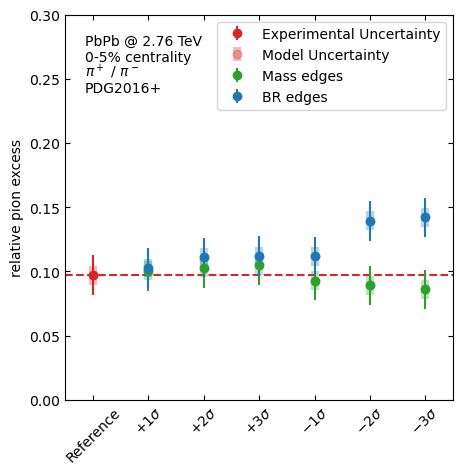

In [65]:
plot_rel_excess_colors(rel_excess, rel_excess_err_exp, rel_excess_err_mod; nsigma=true, QM=QM_bool, edge=true, save=save_plots)


include("Libs/excess_parser.jl");
outfile = QM_bool ? "ExcessData/relative_excess_results_QM.txt" : "ExcessData/relative_excess_results.txt"
write_results_to_file(rel_excess, rel_excess_err_exp, rel_excess_err_mod, outfile)

loaded_results = read_results_from_file(outfile)
println("Reloaded results from ", outfile)
println("rel_excess = ", loaded_results.rel_excess)

## Section to plot down to 0GeV pT

In [66]:
rescale_thermal::Bool = true;
rescale_total_refregion::Bool = true;

#@show dic.pion
use_3d_kernel = false

pT_range = collect(0:0.01:3)

results_pion_cuts = get_results_list(fo, dic_cuts, params, pT_range; interpolate_3d=use_3d_kernel);

REFERENCE_MULT_TOTAL = 296.9204802282646
REFERENCE_MULT_THERMAL = 346.68494311992293

if rescale_thermal
    println("Rescaling to match all thermal spectra in (0.1 - 3.0 GeV/c) range, then match total spectra in (0.5 - 3.0 GeV/c) range.")
    rescaled_thermal_result_pion_cuts = rescale_result_list_thermal(results_pion_cuts; reference_mult = REFERENCE_MULT_THERMAL);
    if rescale_total_refregion
        println("Rescaling total result to match in (0.5 - 3.0 GeV/c) range.")
        rescaled_result_pion_cuts = rescale_result_list(rescaled_thermal_result_pion_cuts; reference_mult = REFERENCE_MULT_TOTAL); 
    else
        rescaled_result_pion_cuts = rescaled_thermal_result_pion_cuts;
    end
else
    if rescale_total_refregion
        println("Rescaling total result to match in (0.5 - 3.0 GeV/c) range.")
        rescaled_result_pion_cuts = rescale_result_list(results_pion_cuts; reference_mult = REFERENCE_MULT_TOTAL);
    else
        rescaled_result_pion_cuts = results_pion_cuts;
    end
end

Rescaling to match all thermal spectra in (0.1 - 3.0 GeV/c) range, then match total spectra in (0.5 - 3.0 GeV/c) range.
Reference thermal multiplicities (0.1 - 3.0 GeV/c): [346.68494311992293, 345.00033911097944, 348.90134213549004, 346.68494311992293, 346.68494311992293, 318.7235953940039, 294.509493881545, 344.3815837686149, 350.26797620197146, 346.68494311992293, 346.68494311992293, 282.5658517928017, 203.42205188107616, 343.81665998411506, 351.73394001823453, 346.68494311992293, 346.68494311992293, 268.7873316986543, 194.90339647590548]
Scaling factors: [1.0, 1.0048829053712947, 0.9936474907147064, 1.0, 1.0, 1.0877291425234878, 1.1771605001615448, 1.006688392933507, 0.9897705947289269, 1.0, 1.0, 1.226917339516801, 1.7042643111406652, 1.0083424786220085, 0.9856454088620227, 1.0, 1.0, 1.2898113200833512, 1.7787527020483767]
Rescaling total result to match in (0.5 - 3.0 GeV/c) range.
Reference multiplicities (0.5 - 3.0 GeV/c): [296.9204802282646, 286.972378176252, 305.61849064962286, 

ResultsList([[(407.7805142321399, 0.004127975143539082), (407.7805142321399, 0.004127975143539082), (408.03221081908026, 0.004246485744247588), (408.6873285243541, 0.005600715346300245), (409.3423497950382, 0.004881452295725175), (409.85342935926207, 0.004414528584346378), (409.544598303307, 0.00538496246178527), (409.23582925761144, 0.005131046916966142), (408.927033212154, 0.0051355118186017235), (406.42054748501096, 0.005232229675094735)  …  (0.05799491292013236, 8.550003821418325e-7), (0.05568896554573375, 8.261047113190158e-7), (0.05338304141213204, 7.546660586266317e-7), (0.051077093378323585, 7.271274762798084e-7), (0.048771145344515016, 6.995888939143453e-7), (0.04779017516274914, 6.866738248327363e-7), (0.04688929378009922, 6.746426796774754e-7), (0.04598841239744936, 6.62611534517737e-7), (0.045087531014799447, 6.50580389355045e-7), (0.04418664963214959, 6.385492441921624e-7)], [(407.38431287566254, 0.004089601863533049), (407.38431287566254, 0.004089601863533049), (407.63652

Spectra masses: 6
Spectra masses: 6


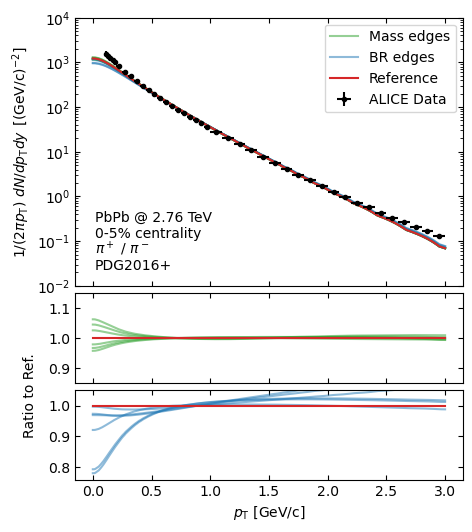

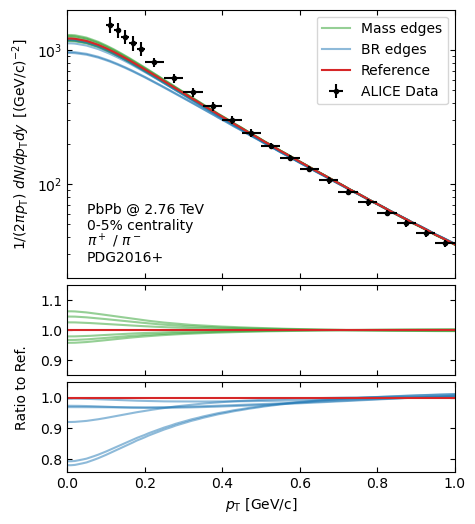

In [67]:
include("Libs/plotter_final.jl");
QM_bool = false
plot_spectra_relative_colors(rescaled_result_pion_cuts, data_pion; QM=QM_bool, save=save_plots)
plot_spectra_relative_colors(rescaled_result_pion_cuts, data_pion; excess=true, QM=QM_bool, save=save_plots)